# Stationary signal $S_t$

A signal $Z_t$ is a stochastic process  
$S_t = f(X_t) + \epsilon$  
  
$\epsilon \sim \mathcal{N}\left(0, \sigma^2_\epsilon \right)$ is error  
$X_t$ are stochastic features

#### Z score price ratio  
$S_t = \hat f(X_t) = \frac{\log P_t^A - \beta \log P_t^B - \hat\mu_t}{\hat\sigma_t}$  
GPT: "where $\beta$ from rolling OLS (or cointegration) and $\hat\mu$, $\hat\sigma$ from a trailing window (no look-ahead)"   

/tmp/ipykernel_420830/533814942.py:11: FutureWarning: YF.download() has changed argument auto_adjust default to True
  self.data = yf.download(ticker, period="10y", interval="1d")
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_420830/533814942.py:11: FutureWarning: YF.download() has changed argument auto_adjust default to True
  self.data = yf.download(ticker, period="10y", interval="1d")
[*********************100%***********************]  1 of 1 completed


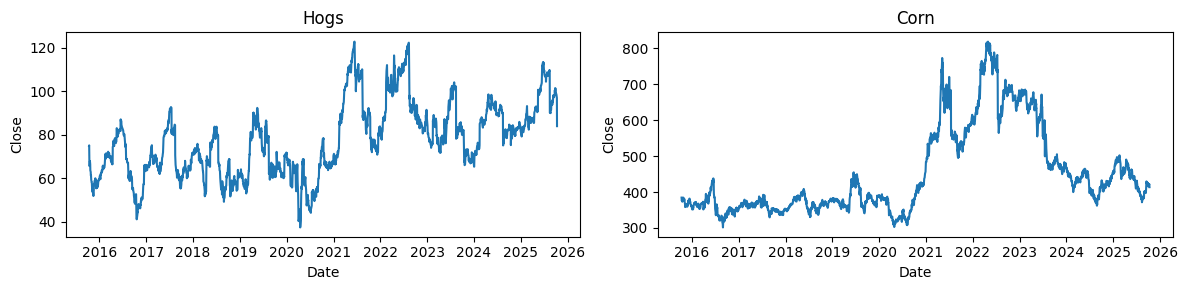

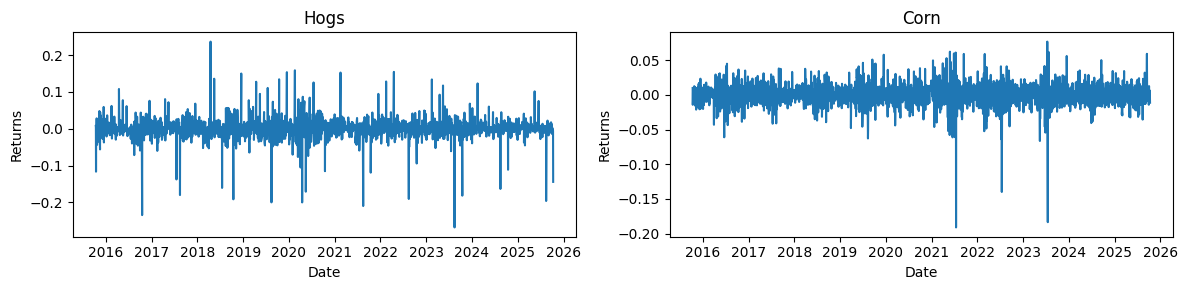

Price Cointegration p-value: 0.0007 True
Returns Cointegration p-value: 0.0000 True


In [1]:
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import coint

class Asset:
    def __init__(self, ticker, name=None):
        self.ticker = ticker
        self.name = name if name else ticker
        self.data = yf.download(ticker, period="10y", interval="1d")
        self.data["Returns"] = self.get_returns()   
        self.data = self.data.iloc[1:]
        self.data["Signal"] = 0.0

    def get_price(self, date):
        return self.data.loc[date]["Close"]
    
    def get_returns(self):
        # log returns
        lr = np.log(self.data["Close"] / self.data["Close"].shift(1))
        return lr
    
    def set_signal(self, signal):
        self.data["Signal"] = signal

    def get_signal(self):
        return self.data["Signal"]
    
    def plot(self, feature="Close", title=None):
        plt.plot(self.data[feature])
        plt.title(title if title else self.name)
        plt.xlabel("Date")
        plt.ylabel(feature)
        plt.show()

class Plot:
    @staticmethod
    def side_by_side(assets, feature="Close"):
        fig, axes = plt.subplots(1, len(assets), figsize=(12, 3))
        for ax, asset in zip(axes, assets):
            ax.plot(asset.data[feature])
            ax.set_title(asset.name)
            ax.set_xlabel("Date")
            ax.set_ylabel(feature)
        plt.tight_layout()
        return fig, axes

A = Asset("HE=F", "Hogs")
B = Asset("ZC=F", "Corn")

fig, axes = Plot.side_by_side([A, B], feature="Close")
plt.show()

fig, axes = Plot.side_by_side([A, B], feature="Returns")
plt.show()

# match data
A.data = A.data.loc[A.data.index.intersection(B.data.index)]
B.data = B.data.loc[B.data.index.intersection(A.data.index)]

_, pvalue, _ = coint(A.data["Close"], B.data["Close"])
print(f"Price Cointegration p-value: {pvalue:.4f}", pvalue < 0.05) # p-value large indicates is not valid

_, pvalue, _ = coint(A.data["Returns"], B.data["Returns"]) 
print(f"Returns Cointegration p-value: {pvalue:.4f}", pvalue < 0.05) # p-value small indicates cointegration so valid pair

In [2]:
# get \hat\beta from OLS regression of A on B
import statsmodels.api as sm
X = sm.add_constant(B.data["Returns"])
model = sm.OLS(A.data["Returns"], X).fit()
beta = model.params.iloc[1]
print(f"Beta = {beta:.4f}")


# get \hat\mu, \hat\sigma from trailing window
window_size = 60
rolling = (A.data["Returns"] - beta * B.data["Returns"]).rolling(window=window_size)
mu = rolling.mean()
sigma = rolling.std()
print(f"Mu = {mu.iloc[-1]:.4f}")
print(f"Sigma = {sigma.iloc[-1]:.4f}")

def S_t(t):
    return (A.data["Returns"].iloc[t] - beta * B.data["Returns"].iloc[t] - mu.iloc[t]) / sigma.iloc[t]

S = np.array([S_t(t) for t in range(len(A.data))])

df = pd.DataFrame({
    "A": A.data["Returns"],
    "B": B.data["Returns"],
    "S": S
})

Beta = 0.1184
Mu = -0.0039
Sigma = 0.0327


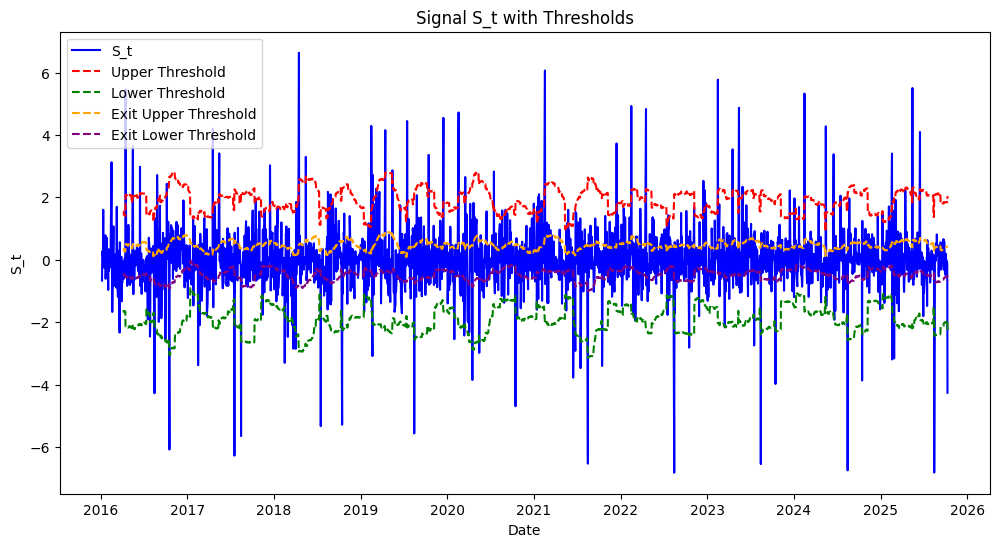

In [3]:
signal_window = df["S"].rolling(window_size)

rolling_mean = signal_window.mean()
rolling_std = signal_window.std()

long_mult = 2
short_mult = long_mult
exit_mult = 0.5

df["upper"] = rolling_mean + long_mult * rolling_std
df["lower"] = rolling_mean - short_mult * rolling_std
df["exit_upper"] = rolling_mean + exit_mult * rolling_std
df["exit_lower"] = rolling_mean - exit_mult * rolling_std

df = df.iloc[window_size-1:]

# plot
plt.figure(figsize=(12, 6))
plt.plot(df["S"], label="S_t", color="blue")
plt.plot(df["upper"], label="Upper Threshold", color="red", linestyle="--")
plt.plot(df["lower"], label="Lower Threshold", color="green", linestyle="--")
plt.plot(df["exit_upper"], label="Exit Upper Threshold", color="orange", linestyle="--")
plt.plot(df["exit_lower"], label="Exit Lower Threshold", color="purple", linestyle="--")
plt.title("Signal S_t with Thresholds")
plt.xlabel("Date")
plt.ylabel("S_t")
plt.legend()
plt.show()

# Classify $S_t$

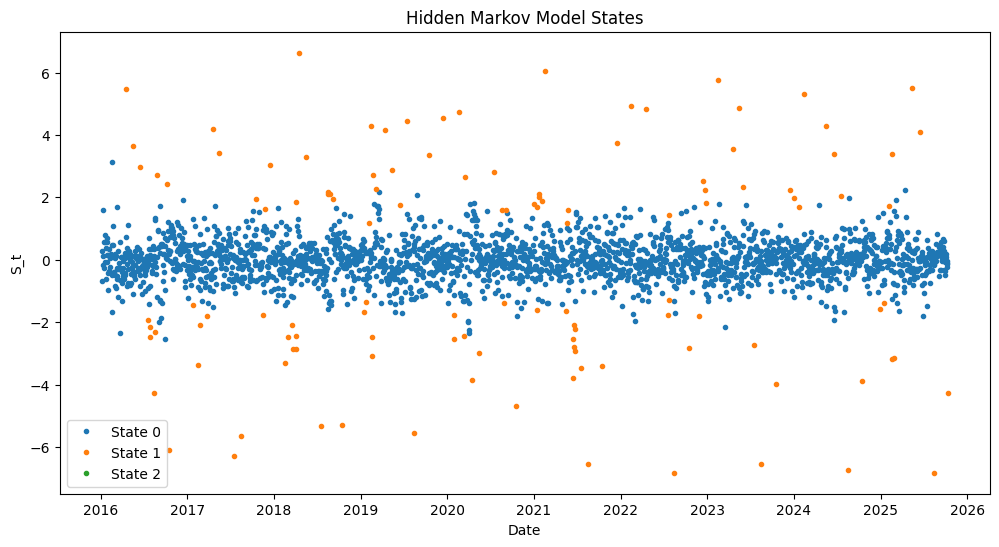

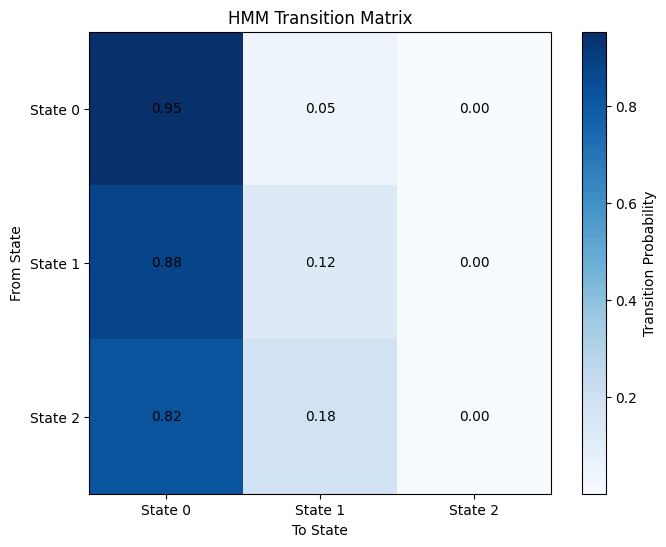

In [4]:
# hmm
from hmmlearn import hmm

df["State"] = 0
buy_flag = df["S"] < df["lower"]
sell_flag = df["S"] > df["upper"]
df.loc[buy_flag, "State"] = 1
df.loc[sell_flag, "State"] = 2

model = hmm.GaussianHMM(n_components=3, covariance_type="full", n_iter=1000)
X = df["State"].values.reshape(-1, 1)
model.fit(X)
hidden_states = model.predict(X)

df = df.copy()
df["Hidden_State"] = hidden_states

plt.figure(figsize=(12, 6))
for state in range(model.n_components):
    state_mask = df["Hidden_State"] == state
    plt.plot(df.index[state_mask], df["S"][state_mask], ".", label=f"State {state}")
plt.title("Hidden Markov Model States")
plt.xlabel("Date")
plt.ylabel("S_t")
plt.legend()
plt.show()

# plot transition matrix
transmat = model.transmat_
plt.figure(figsize=(8, 6))
plt.imshow(transmat, cmap="Blues", interpolation="nearest")
plt.colorbar(label="Transition Probability")
plt.xticks(np.arange(model.n_components), [f"State {i}" for i in range(model.n_components)])
plt.yticks(np.arange(model.n_components), [f"State {i}" for i in range(model.n_components)])
plt.title("HMM Transition Matrix")
plt.xlabel("To State")
plt.ylabel("From State")
for i in range(model.n_components):
    for j in range(model.n_components):
        plt.text(j, i, f"{transmat[i, j]:.2f}", ha="center", va="center", color="black")
plt.show()

In [5]:
#